# 1. Importing Libraries


In [25]:

# 1. Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


# 2. Loading Dataset


In [26]:
# 2. Loading Dataset

df = pd.read_csv("GlobalWeatherRepository.CSV")

print("Dataset Loaded Successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Loaded Successfully!

Dataset Shape:
(170928, 41)

First 5 Rows:


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy,...,8.4,26.6,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy,...,1.1,2.0,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny,...,10.4,18.4,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle,...,0.7,0.9,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy,...,183.4,262.3,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170928 entries, 0 to 170927
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   country                       170928 non-null  object 
 1   location_name                 170928 non-null  object 
 2   latitude                      170928 non-null  float64
 3   longitude                     170928 non-null  float64
 4   timezone                      170928 non-null  object 
 5   last_updated_epoch            170928 non-null  int64  
 6   last_updated                  170928 non-null  object 
 7   temperature_celsius           170928 non-null  float64
 8   temperature_fahrenheit        170928 non-null  float64
 9   condition_text                170928 non-null  object 
 10  wind_mph                      170928 non-null  float64
 11  wind_kph                      170928 non-null  float64
 12  wind_degree           

,latitude,longitude,last_updated_epoch,temperature_celsius,temperature_fahrenheit,wind_mph,wind_kph,wind_degree,pressure_mb,pressure_in,...,gust_kph,air_quality_Carbon_Monoxide,air_quality_Ozone,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,moon_illumination
count,170928.000000,170928.000000,1.709280e+05,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,...,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000,170928.000000
mean,19.283424,21.805043,1.753891e+09,21.445260,70.602908,7.872443,12.673318,170.146705,1014.037273,29.943998,...,18.135030,414.987347,57.797225,13.876022,9.500995,22.484948,44.982984,1.637965,2.464658,50.058346
std,24.373383,65.766968,2.196145e+07,9.271741,16.689010,6.826576,10.982650,103.263264,9.871950,0.291454,...,13.309821,693.107740,31.377326,22.069114,32.326288,34.190678,139.406581,0.908481,2.344791,35.135038
min,-41.300000,-175.200000,1.715849e+09,-29.800000,-21.600000,2.200000,3.600000,1.000000,771.000000,22.760000,...,3.600000,-9999.000000,0.000000,0.000000,-9999.000000,0.100000,-1848.150000,1.000000,1.000000,0.000000
25%,4.050300,-6.836100,1.734949e+09,16.200000,61.100000,3.800000,6.100000,81.000000,1010.000000,29.830000,...,10.100000,174.812500,38.000000,1.700000,1.050000,6.700000,9.500000,1.000000,1.000000,15.000000
50%,17.250000,21.433300,1.753863e+09,23.600000,74.400000,6.500000,10.400000,164.000000,1014.000000,29.930000,...,15.200000,264.550000,54.000000,5.450000,2.300000,12.950000,18.500000,1.000000,2.000000,50.000000
75%,40.400000,49.882200,1.772865e+09,27.700000,81.800000,10.700000,17.300000,256.000000,1018.000000,30.060000,...,24.100000,420.850000,73.000000,15.800000,7.500000,25.600000,38.295000,2.000000,3.000000,85.000000
max,65.300000,179.220000,1.791870e+09,79.300000,174.700000,1841.200000,2963.200000,360.000000,3006.000000,88.770000,...,2970.400000,38879.398000,480.700000,427.700000,521.330000,1614.100000,6037.290000,6.000000,10.000000,100.000000


# 3. Data Cleaning, Outlier Detection and Normalization


Missing Values Before Cleaning:
country                         0
location_name                   0
latitude                        0
longitude                       0
timezone                        0
last_updated_epoch              0
last_updated                    0
temperature_celsius             0
temperature_fahrenheit          0
condition_text                  0
wind_mph                        0
wind_kph                        0
wind_degree                     0
wind_direction                  0
pressure_mb                     0
pressure_in                     0
precip_mm                       0
precip_in                       0
humidity                        0
cloud                           0
feels_like_celsius              0
feels_like_fahrenheit           0
visibility_km                   0
visibility_miles                0
uv_index                        0
gust_mph                        0
gust_kph                        0
air_quality_Carbon_Monoxide     0
air_quality_Ozon

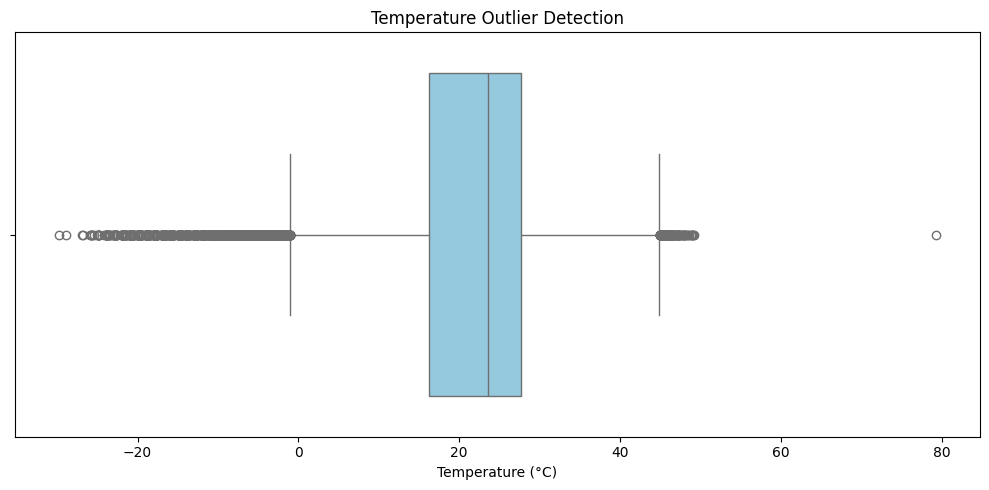


Normalized Dataset:


,latitude,longitude,last_updated_epoch,temperature_celsius,temperature_fahrenheit,wind_mph,wind_kph,wind_degree,pressure_mb,pressure_in,...,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,moon_illumination,year,month,day
0,0.625134,0.720348,-1.732219,0.555964,0.551088,0.062631,0.057061,1.625494,-0.206370,-0.185270,...,-0.578911,-0.436892,-0.411954,-0.132080,-0.702234,-0.624645,0.140648,-1.39675,-0.526609,0.030651
1,0.904538,-0.030183,-1.732219,-0.263733,-0.263822,-0.142450,-0.134150,1.451181,-0.206370,-0.219581,...,-0.587974,-0.441559,-0.625463,-0.308667,-0.702234,-0.624645,0.140648,-1.39675,-0.526609,0.030651
2,0.717037,-0.285175,-1.732219,0.167686,0.167601,0.223767,0.220957,1.063821,-0.307668,-0.322514,...,2.321078,0.179270,-0.353458,-0.190943,-0.702234,-0.624645,0.140648,-1.39675,-0.526609,0.030651
3,0.952541,-0.308439,-1.732219,-1.633491,-1.635986,-0.069207,-0.070413,0.434360,-0.712857,-0.665622,...,-0.556255,-0.436892,-0.637162,-0.316563,-0.702234,-0.624645,0.140648,-1.39675,-0.526609,0.030651
4,-1.153861,-0.130386,-1.732219,0.491251,0.491168,0.033334,0.029745,-0.195101,-0.307668,-0.322514,...,2.665451,1.024158,4.706415,1.559853,3.700732,3.213661,0.140648,-1.39675,-0.526609,0.030651



Cleaned Dataset Shape: (170928, 44)
Remaining Missing Values: 0

Data Cleaning Completed Successfully!


In [27]:

# 3. Data Cleaning, Outlier Detection and Normalization

# Create a working copy of the dataset
df = df.copy()

# 1. Check Missing Values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# 2. Handle Invalid Air Quality Values
air_quality_cols = [
    'air_quality_Carbon_Monoxide',
    'air_quality_Ozone',
    'air_quality_Nitrogen_dioxide',
    'air_quality_Sulphur_dioxide',
    'air_quality_PM2.5',
    'air_quality_PM10'
]

# Negative pollution concentrations are invalid
for col in air_quality_cols:
    df.loc[df[col] < 0, col] = np.nan

# Replace missing numeric values with their median
df.fillna(df.median(numeric_only=True), inplace=True)

# 3. Check and Remove Duplicates
print("\nDuplicate Rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# 4. Convert Date Column
df['last_updated'] = pd.to_datetime(
    df['last_updated'],
    errors='coerce'
)

df['year'] = df['last_updated'].dt.year
df['month'] = df['last_updated'].dt.month
df['day'] = df['last_updated'].dt.day

# 5. Temperature Outlier Detection Using IQR
Q1 = df['temperature_celsius'].quantile(0.25)
Q3 = df['temperature_celsius'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['temperature_celsius'] < lower) |
    (df['temperature_celsius'] > upper)
]

print("\nNumber of Temperature Outliers:", len(outliers))
print("Lower Temperature Bound:", round(lower, 2))
print("Upper Temperature Bound:", round(upper, 2))

# 6. Visualize Temperature Outliers
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['temperature_celsius'],
    color='skyblue'
)

plt.title("Temperature Outlier Detection")
plt.xlabel("Temperature (°C)")
plt.tight_layout()
plt.show()

# Keep outliers for anomaly detection and forecasting

# 7. Normalize Numeric Features
numeric_cols = df.select_dtypes(include=np.number).columns

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df[numeric_cols])

scaled_df = pd.DataFrame(
    scaled_data,
    columns=numeric_cols,
    index=df.index
)

print("\nNormalized Dataset:")
display(scaled_df.head())

# 8. Final Cleaning Summary
print("\nCleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())
print("\nData Cleaning Completed Successfully!")


# 4. Exploratory Data Analysis (EDA)

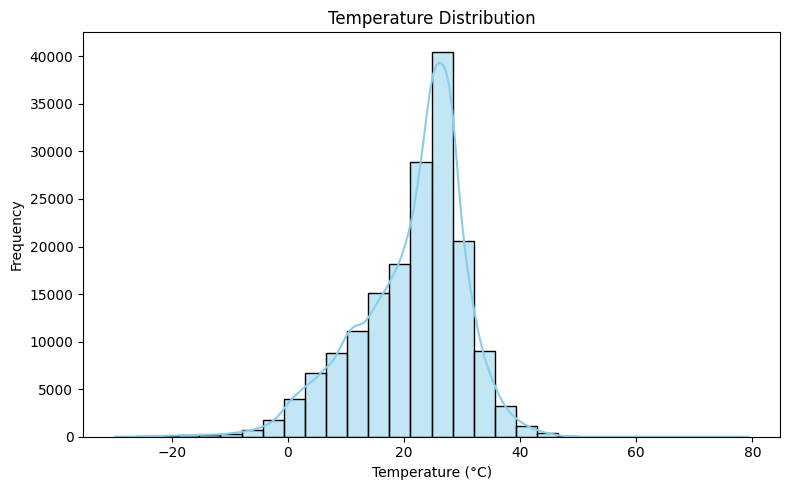

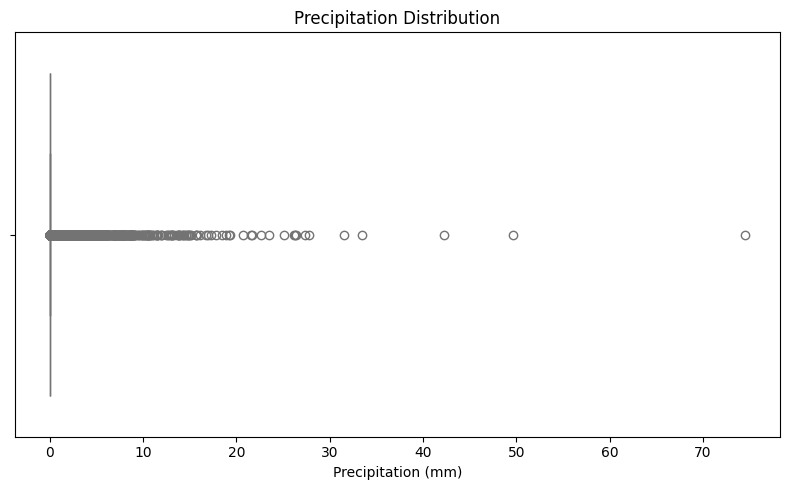

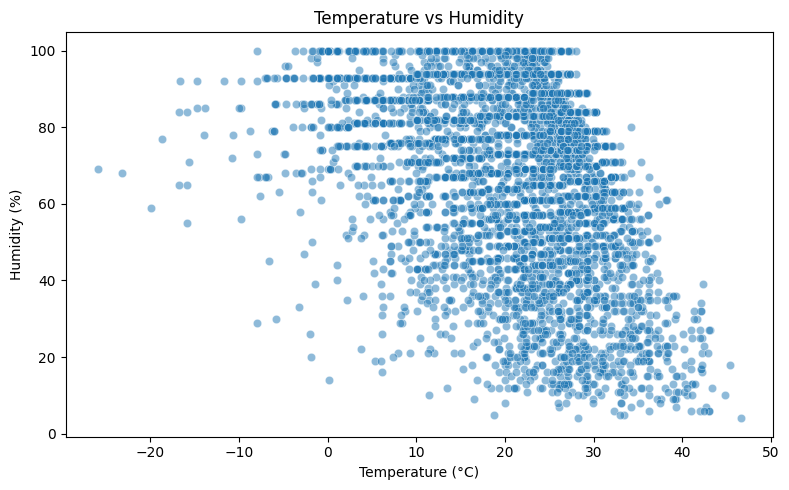

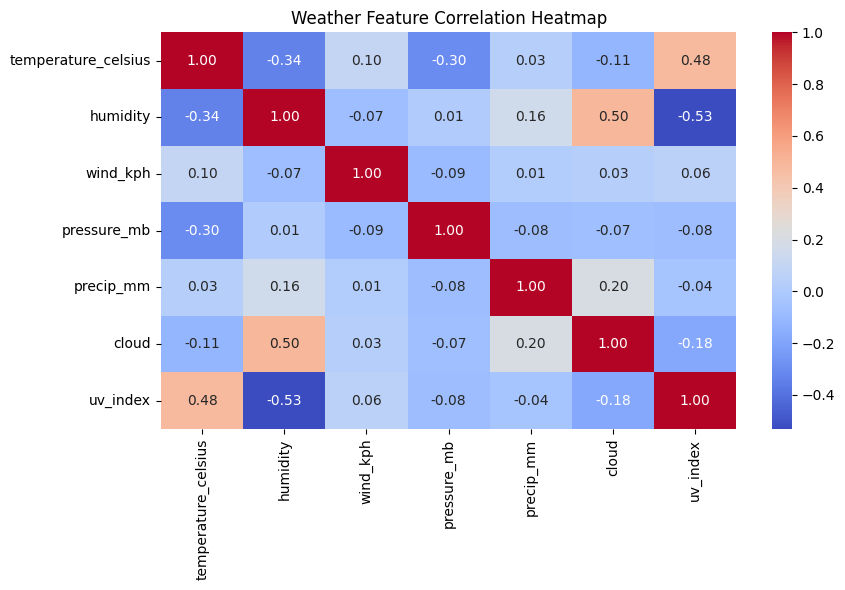

Exploratory Data Analysis Completed Successfully!


In [28]:

# 4. Exploratory Data Analysis (EDA)

# 1. Temperature Distribution
plt.figure(figsize=(8,5))
sns.histplot(
    df['temperature_celsius'],
    bins=30,
    kde=True,
    color='skyblue'
)
plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 2. Precipitation Distribution
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df['precip_mm'],
    color='lightgreen'
)
plt.title("Precipitation Distribution")
plt.xlabel("Precipitation (mm)")
plt.tight_layout()
plt.show()

# 3. Temperature vs Humidity
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df.sample(
        n=min(5000, len(df)),
        random_state=42
    ),
    x='temperature_celsius',
    y='humidity',
    alpha=0.5
)
plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.tight_layout()
plt.show()

# 4. Weather Feature Correlation Heatmap
corr_features = [
    'temperature_celsius',
    'humidity',
    'wind_kph',
    'pressure_mb',
    'precip_mm',
    'cloud',
    'uv_index'
]

plt.figure(figsize=(9,6))
sns.heatmap(
    df[corr_features].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title("Weather Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Exploratory Data Analysis Completed Successfully!")


# 5. Advanced EDA – Anomaly Detection

Anomaly Detection Results:
anomaly
 1    169218
-1      1710
Name: count, dtype: int64

Number of Anomalies: 1710
Number of Normal Observations: 169218


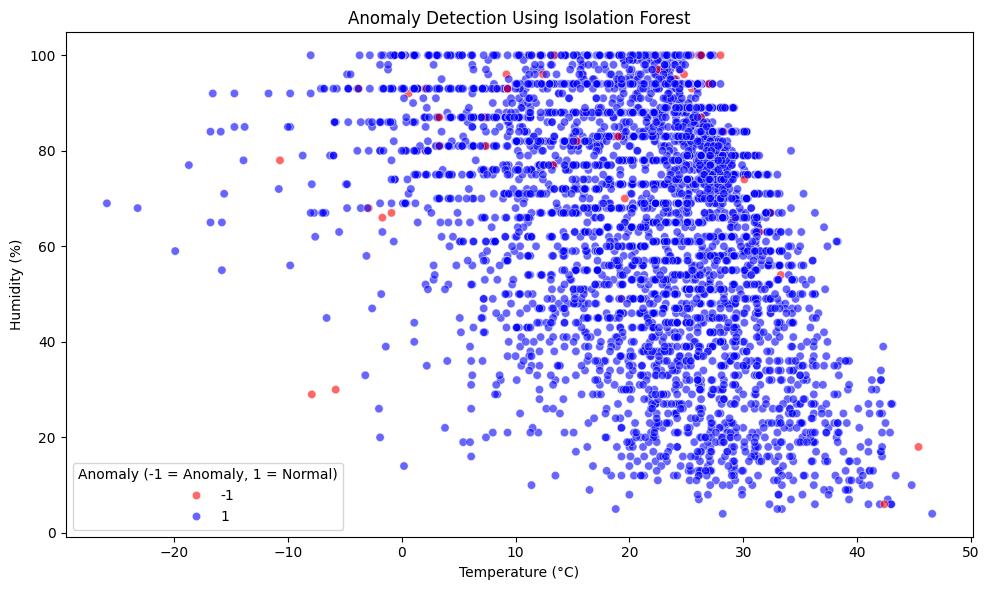


Anomaly Detection Completed Successfully!


In [29]:

# 5. Advanced EDA – Anomaly Detection

# Select Weather Features
features = [
    'temperature_celsius',
    'humidity',
    'wind_kph',
    'pressure_mb',
    'precip_mm'
]

# Initialize Isolation Forest Model
iso = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# Detect Anomalies
df['anomaly'] = iso.fit_predict(df[features])

# Display Anomaly Counts
print("Anomaly Detection Results:")
print(df['anomaly'].value_counts())

print("\nNumber of Anomalies:",
      (df['anomaly'] == -1).sum())

print("Number of Normal Observations:",
      (df['anomaly'] == 1).sum())

# Visualize Anomalies
sample_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=sample_df,
    x='temperature_celsius',
    y='humidity',
    hue='anomaly',
    palette={1: 'blue', -1: 'red'},
    alpha=0.6
)

plt.title("Anomaly Detection Using Isolation Forest")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.legend(title="Anomaly (-1 = Anomaly, 1 = Normal)")
plt.tight_layout()
plt.show()

print("\nAnomaly Detection Completed Successfully!")


# 6. Climate Analysis

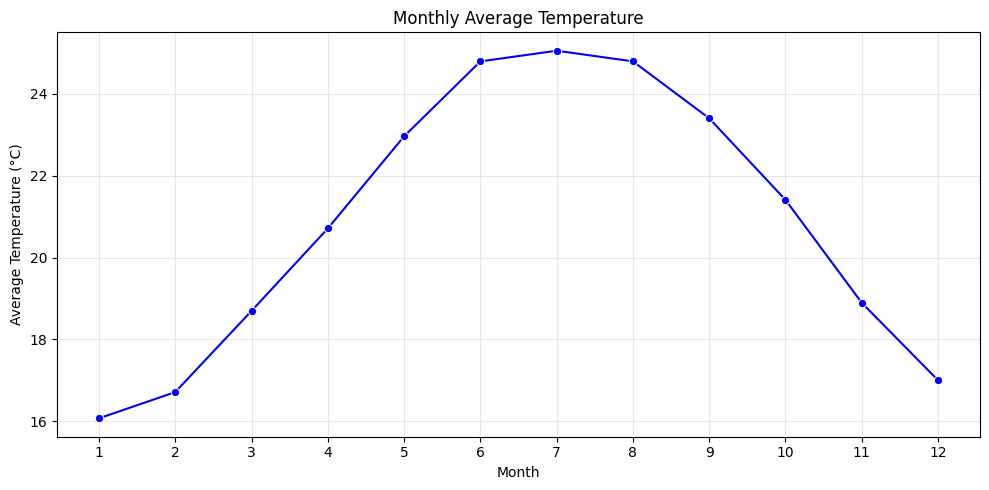

Monthly Average Temperature:


,Average Temperature (°C)
month,
1,16.07
2,16.71
3,18.70
4,20.71
5,22.96
6,24.79
7,25.05
8,24.79
9,23.40


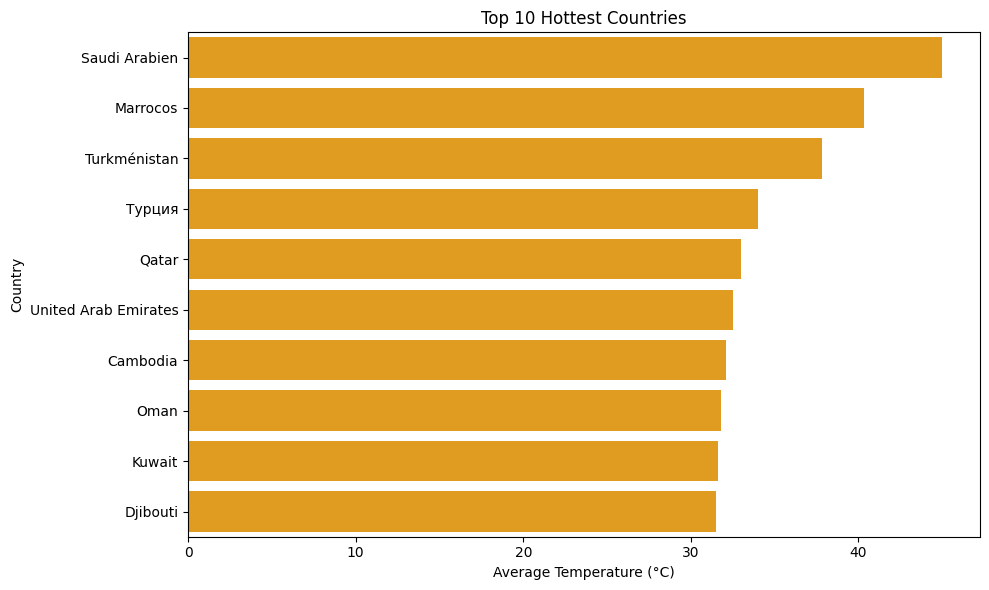


Top 10 Hottest Countries:


,country,temperature_celsius
0,Saudi Arabien,45.00
1,Marrocos,40.30
2,Turkménistan,37.80
3,Турция,34.00
4,Qatar,32.97
5,United Arab Emirates,32.53
6,Cambodia,32.09
7,Oman,31.80
8,Kuwait,31.64
9,Djibouti,31.49



Climate Analysis Completed Successfully!


In [30]:

# 6. Climate Analysis

# 1. Monthly Average Temperature
monthly_temp = (
    df.groupby('month')['temperature_celsius']
    .mean()
    .reindex(range(1, 13))
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_temp.index,
    y=monthly_temp.values,
    marker='o',
    color='blue'
)

plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Monthly Average Temperature:")
display(monthly_temp.to_frame(name="Average Temperature (°C)").round(2))


# 2. Top 10 Hottest Countries
country_temp = (
    df.groupby('country')['temperature_celsius']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_temp,
    x='temperature_celsius',
    y='country',
    color='orange'
)

plt.title("Top 10 Hottest Countries")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

print("\nTop 10 Hottest Countries:")
display(country_temp.round(2))

print("\nClimate Analysis Completed Successfully!")


# 7. Geographical Pattern Analysis

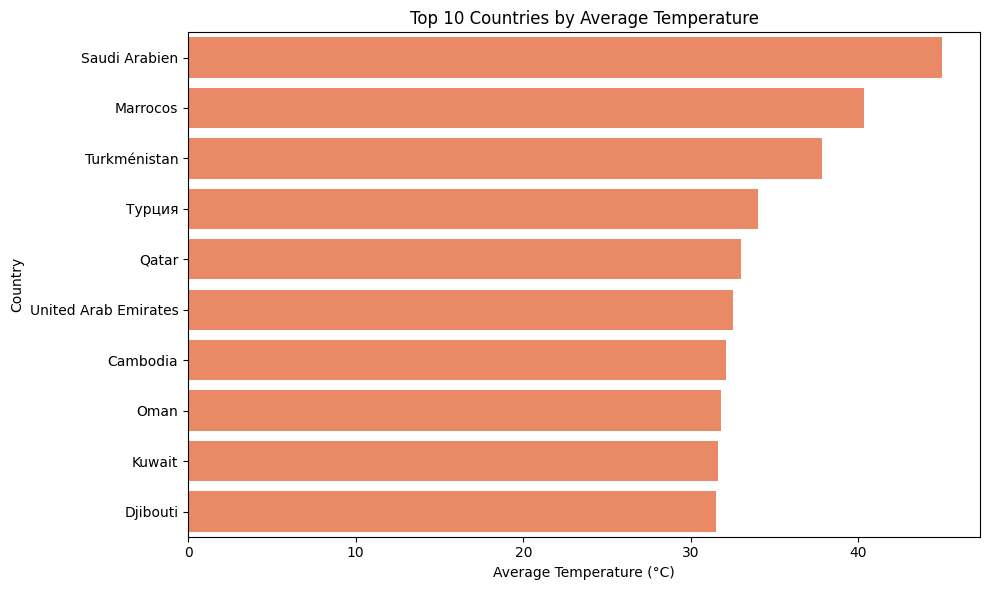

Top 10 Countries by Average Temperature:


,country,temperature_celsius
0,Saudi Arabien,45.00
1,Marrocos,40.30
2,Turkménistan,37.80
3,Турция,34.00
4,Qatar,32.97
5,United Arab Emirates,32.53
6,Cambodia,32.09
7,Oman,31.80
8,Kuwait,31.64
9,Djibouti,31.49



Geographical Pattern Analysis Completed Successfully!


In [31]:

# 7. Geographical Pattern Analysis

# Calculate Average Temperature by Country
geo_temp = (
    df.groupby('country')['temperature_celsius']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Visualize Top 10 Countries by Temperature
plt.figure(figsize=(10, 6))

sns.barplot(
    data=geo_temp,
    x='temperature_celsius',
    y='country',
    color='coral'
)

plt.title("Top 10 Countries by Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# Display Results
print("Top 10 Countries by Average Temperature:")
display(geo_temp.round(2))

print("\nGeographical Pattern Analysis Completed Successfully!")


# 8. Environmental Impact Analysis

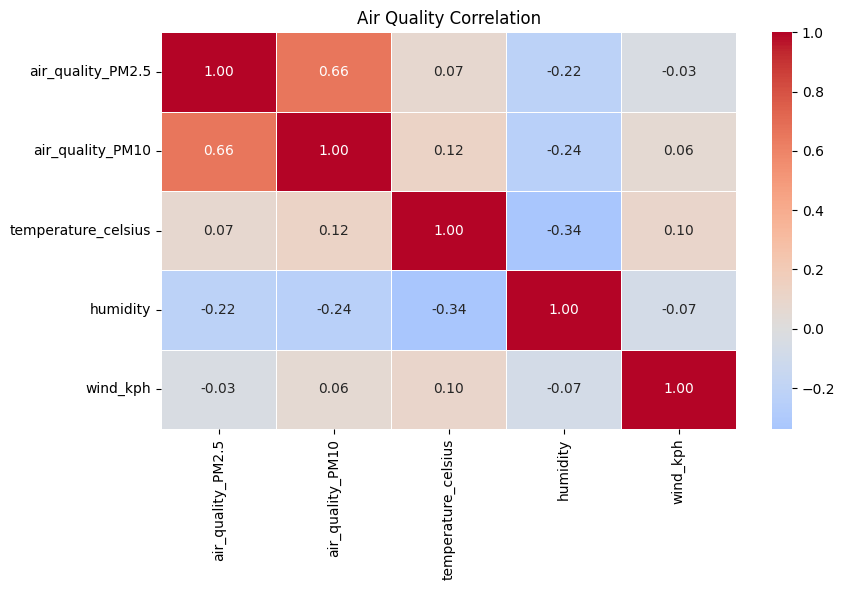

Air Quality Correlation Matrix:


,air_quality_PM2.5,air_quality_PM10,temperature_celsius,humidity,wind_kph
air_quality_PM2.5,1.000,0.660,0.070,-0.223,-0.033
air_quality_PM10,0.660,1.000,0.118,-0.243,0.062
temperature_celsius,0.070,0.118,1.000,-0.338,0.101
humidity,-0.223,-0.243,-0.338,1.000,-0.072
wind_kph,-0.033,0.062,0.101,-0.072,1.000



Environmental Impact Analysis Completed Successfully!


In [32]:

# 8. Environmental Impact Analysis

# Select Air Quality and Weather Features
air_quality_features = [
    'air_quality_PM2.5',
    'air_quality_PM10',
    'temperature_celsius',
    'humidity',
    'wind_kph'
]

# Calculate Correlation Matrix
air_quality_corr = df[air_quality_features].corr()

# Visualize Correlation Heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    air_quality_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title("Air Quality Correlation")
plt.tight_layout()
plt.show()

# Display Correlation Values
print("Air Quality Correlation Matrix:")
display(air_quality_corr.round(3))

print("\nEnvironmental Impact Analysis Completed Successfully!")


# 9. Feature Importance

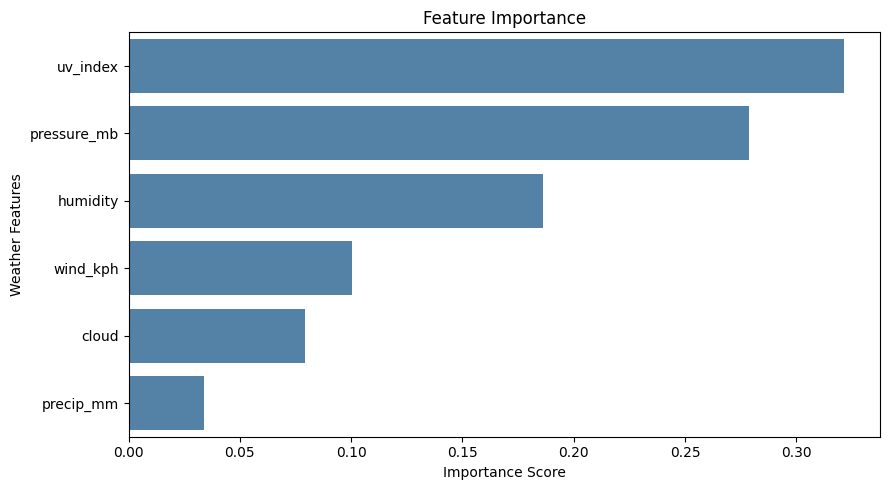

Feature Importance Results:


,Feature,Importance
4,uv_index,0.3216
2,pressure_mb,0.2787
0,humidity,0.1863
1,wind_kph,0.1003
3,cloud,0.0791
5,precip_mm,0.0340



Most Important Feature: uv_index

Feature Importance Analysis Completed Successfully!


In [33]:

# 9. Feature Importance

# Define Target Variable
target = 'temperature_celsius'

# Select Weather Features
feature_cols = [
    'humidity',
    'wind_kph',
    'pressure_mb',
    'cloud',
    'uv_index',
    'precip_mm'
]

X = df[feature_cols]
y = df[target]

# Train Random Forest Regressor
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X, y)

# Calculate Feature Importance
importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

# Visualize Feature Importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Weather Features")
plt.tight_layout()
plt.show()

# Display Feature Importance Table
print("Feature Importance Results:")
display(importance.round(4))

# Identify Most Important Feature
print("\nMost Important Feature:",
      importance.iloc[0]['Feature'])

print("\nFeature Importance Analysis Completed Successfully!")


# 10. Spatial Analysis

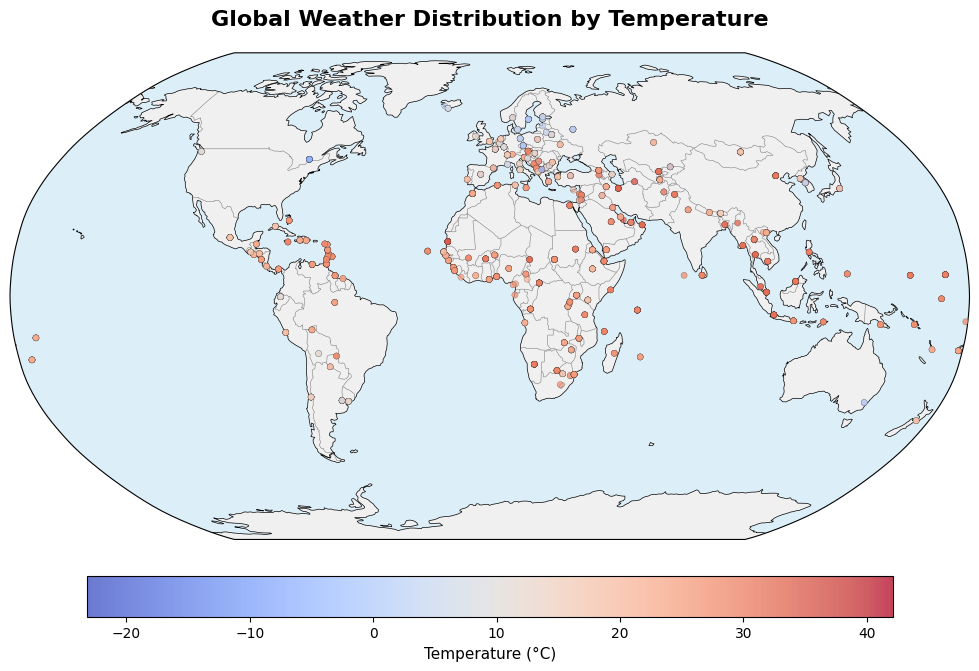

Spatial Analysis Summary
-----------------------------------
Total valid observations: 170928
Locations plotted: 1000
Countries represented: 211
Average temperature: 21.45 °C
Minimum temperature: -29.8 °C
Maximum temperature: 79.3 °C

Spatial Analysis Completed Successfully!


In [36]:

# 10. Spatial Analysis - Global Weather Distribution

import sys
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Install required mapping libraries
subprocess.run(
    [sys.executable, "-m", "pip", "-q", "install",
     "geopandas", "cartopy"],
    check=True
)

import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Prepare spatial data
spatial_df = df[
    ['country', 'latitude', 'longitude', 'temperature_celsius']
].copy()

for col in ['latitude', 'longitude', 'temperature_celsius']:
    spatial_df[col] = pd.to_numeric(
        spatial_df[col], errors='coerce'
    )

spatial_df = spatial_df.dropna()

# Remove invalid geographical coordinates
spatial_df = spatial_df[
    spatial_df['latitude'].between(-90, 90) &
    spatial_df['longitude'].between(-180, 180)
]

if spatial_df.empty:
    raise ValueError("No valid weather locations available.")

# 2. Sample observations for clearer visualization
sample_df = spatial_df.sample(
    n=min(1000, len(spatial_df)),
    random_state=42
)

# 3. Create world map
fig = plt.figure(figsize=(16, 8))
ax = plt.axes(projection=ccrs.Robinson())

ax.set_global()

# World boundaries without online map tiles
ax.add_feature(
    cfeature.LAND,
    facecolor='#f0f0f0',
    zorder=0
)
ax.add_feature(
    cfeature.OCEAN,
    facecolor='#dceef8',
    zorder=0
)
ax.add_feature(
    cfeature.BORDERS,
    linewidth=0.4,
    edgecolor='gray'
)
ax.coastlines(linewidth=0.5)

# 4. Plot weather locations colored by temperature
points = ax.scatter(
    sample_df['longitude'],
    sample_df['latitude'],
    c=sample_df['temperature_celsius'],
    cmap='coolwarm',
    s=20,
    alpha=0.75,
    edgecolors='black',
    linewidths=0.15,
    transform=ccrs.PlateCarree(),
    zorder=3
)

# 5. Add temperature legend
colorbar = plt.colorbar(
    points,
    ax=ax,
    orientation='horizontal',
    pad=0.06,
    shrink=0.65
)
colorbar.set_label('Temperature (°C)', fontsize=11)

# 6. Title
plt.title(
    'Global Weather Distribution by Temperature',
    fontsize=16,
    fontweight='bold',
    pad=20
)

# 7. Save high-quality figure
plt.savefig(
    'global_weather_spatial_analysis.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 8. Print spatial analysis summary
print("Spatial Analysis Summary")
print("-" * 35)
print("Total valid observations:", len(spatial_df))
print("Locations plotted:", len(sample_df))
print("Countries represented:", spatial_df['country'].nunique())
print(
    "Average temperature:",
    round(spatial_df['temperature_celsius'].mean(), 2),
    "°C"
)
print(
    "Minimum temperature:",
    spatial_df['temperature_celsius'].min(),
    "°C"
)
print(
    "Maximum temperature:",
    spatial_df['temperature_celsius'].max(),
    "°C"
)

print("\nSpatial Analysis Completed Successfully!")


# 11. Forecasting Models

Total Calendar Days: 881
Observed Days: 880
Missing Days: 1

Daily Average Temperature Series:


,Average Temperature (°C)
last_updated,
2024-05-16,23.767196
2024-05-17,24.451648
2024-05-18,25.355610
2024-05-19,25.270103
2024-05-20,25.430769
2024-05-21,25.383077
2024-05-22,25.123077
2024-05-23,25.066154
2024-05-24,25.088718


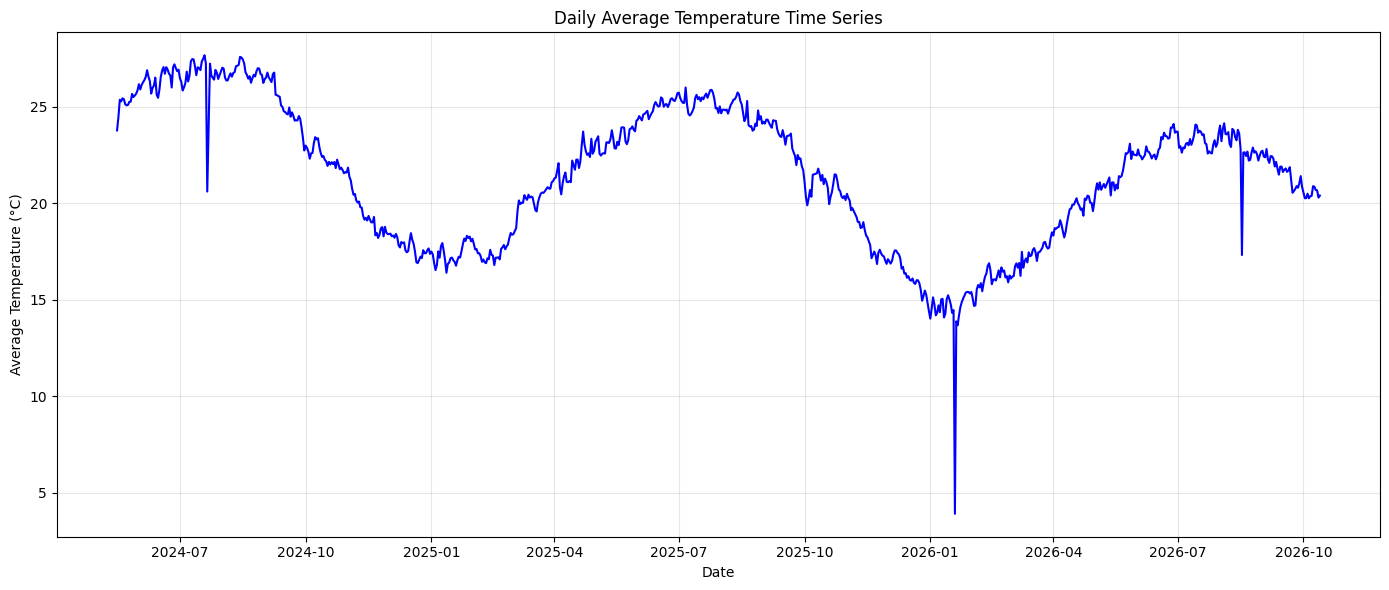


Daily Temperature Series Created Successfully!


In [35]:

# 11. Forecasting Models
# Daily Average Temperature Time Series

import pandas as pd
import matplotlib.pyplot as plt

# Convert date column to datetime
df['last_updated'] = pd.to_datetime(
    df['last_updated'],
    errors='coerce'
)

# Calculate daily average temperature
daily_temp = (
    df.dropna(subset=['last_updated', 'temperature_celsius'])
    .set_index('last_updated')['temperature_celsius']
    .resample('D')
    .mean()
    .sort_index()
)

# Check missing dates
print("Total Calendar Days:", len(daily_temp))
print("Observed Days:", daily_temp.notna().sum())
print("Missing Days:", daily_temp.isna().sum())

# Fill missing dates for a continuous daily series
daily_temp = daily_temp.interpolate(method='time')

# Display first 10 daily temperatures
print("\nDaily Average Temperature Series:")
display(daily_temp.head(10).to_frame(
    name='Average Temperature (°C)'
))

# Plot daily average temperature
plt.figure(figsize=(14, 6))

plt.plot(
    daily_temp.index,
    daily_temp.values,
    color='blue',
    linewidth=1.5
)

plt.title("Daily Average Temperature Time Series")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDaily Temperature Series Created Successfully!")
